# Reconstruct data from an independently discretised instrument
Run with OneSimulation, NumPy and Matplotlib installed.
Vary the true blur width or noise seed. Decide which feature persists across plausible instruments.

True width 0.045: minimum grid RMS error 0.01013
True width 0.065: minimum grid RMS error 0.18949


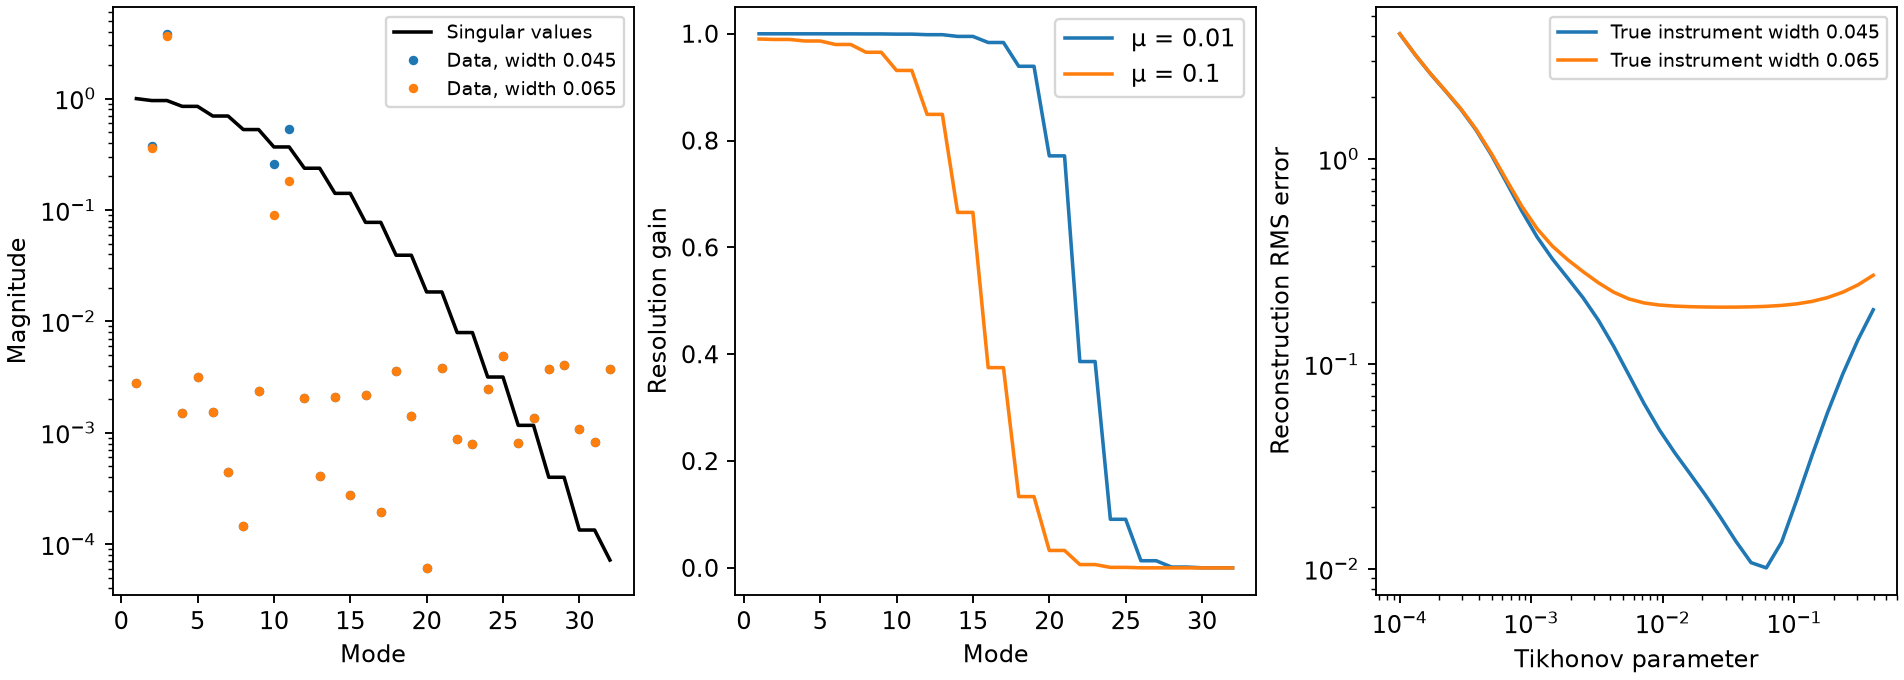

In [1]:
"""Observe model error in a periodic deblurring experiment on different grids."""
import matplotlib.pyplot as plt
import numpy as np
from onesim.numerics.linear.matrices.dense_linear_algebra import solve_dense

def instrument(receivers, sources, width):
    delta = (receivers[:, None] - sources[None, :] + 0.5) % 1 - 0.5
    kernel = np.exp(-(delta/width)**2/2)
    return kernel / kernel.sum(axis=1)[:, None]

def signal(x):
    return np.cos(2*np.pi*x) + 0.4*np.sin(10*np.pi*x)

fine = (np.arange(1024)+0.5)/1024
coarse = (np.arange(32)+0.5)/32
design = instrument(coarse, coarse, 0.045)
rng = np.random.default_rng(17)
noise = rng.normal(0, 0.002, coarse.size)
strengths = np.logspace(-4, -0.4, 32)
fig, (picard, resolution, ax) = plt.subplots(1, 3, figsize=(11.2, 4), layout="constrained")
left, singular, _ = np.linalg.svd(design, full_matrices=False)
indices = np.arange(1, len(singular)+1)
picard.semilogy(indices, singular, color="black", label="Singular values")
for trial in [0.01, 0.1]:
    gain = singular**2 / (singular**2 + trial**2)
    resolution.plot(indices, gain, label=f"μ = {trial:g}")
resolution.set(xlabel="Mode", ylabel="Resolution gain")
resolution.legend()
for width in [0.045, 0.065]:
    data = instrument(coarse, fine, width) @ signal(fine) + noise
    picard.semilogy(indices, abs(left.T @ data), ".", label=f"Data, width {width}")
    errors = []
    for mu in strengths:
        state = solve_dense(design.T @ design + mu**2*np.eye(coarse.size), design.T @ data)
        errors.append(np.linalg.norm(state-signal(coarse))/np.sqrt(coarse.size))
    print(f"True width {width:.3f}: minimum grid RMS error {min(errors):.5f}")
    ax.loglog(strengths, errors, label=f"True instrument width {width}")
ax.set(xlabel="Tikhonov parameter", ylabel="Reconstruction RMS error")
ax.legend(fontsize=8)
picard.set(xlabel="Mode", ylabel="Magnitude")
picard.legend(fontsize=8)
fig.savefig("numerics-inverse-blur.png", dpi=170)
